# Module 04 : Statistiques descriptives et inférentielles

## Où on en est de notre question de recherche ?

Depuis le module 02, nous sommes en train de travailler sur une question :

> **Est-ce que le télétravail contribue à une meilleure performance des entreprises ?**

Nous avons déjà observé, *dans notre échantillon*, que les entreprises qui pratiquent le télétravail présentent **en moyenne une rentabilité et une satisfaction RH plus élevées**. Nous avons également représenté ces différences graphiquement au module 03. Cependant, il reste à comprendre si **les différences que nous observons sont suffisamment importantes pour penser qu'elles existent au-delà de notre échantillon ?** ou **pourraient-elles simplement être dues au hasard de l'échantillonnage ?** C'est exactement la question à laquelle répond un **test d'hypothèse statistique** ; l'objet de ce module.

L'objectif de ce module est de :

- décrire les données : comprendre leur centre, leur dispersion et leur distribution ;
- utiliser des tests statistiques pour déterminer si les différences observées sont compatibles avec le hasard.


**Avant de commencer**, consultez le [README de ce module](README.md).

Nous allons ensuite importer les bibliothèques et les modules dont nous aurons besoin, charger notre jeu de données et vérifier les premières lignes :


In [1]:
import pandas as pd                               # Bibliothèque pandas
import numpy as np                                # Bibliothèque numpy
import matplotlib.pyplot as plt               # Bibliothèque matplotlib
from scipy import stats                           # Module stats de scipy pour effectuer des analyses statistiques, calculer des lois de probabilité et réaliser des tests d'hypothèses

df = pd.read_csv("../../assets/datasets/entreprises_panel.csv")
df.head(3)


,entreprise_id,annee,secteur,region,annee_creation,teletravail,effectifs,chiffre_affaires_keur,rentabilite,satisfaction_rh
0,E001,2019,Industrie,Occitanie,2018,1,529,115830.2,0.1706,7.7
1,E001,2020,Industrie,Occitanie,2018,1,590,125110.5,0.1497,6.7
2,E001,2021,Industrie,Occitanie,2018,1,610,123760.0,0.1594,5.5


**Pour rappel :**

- `pandas` est une bibliothèque Python qui sert à analyser et à transformer des données sous forme de tableaux (lignes et colonnes), comme une feuille Excel.
- `numpy` est la bibliothèque Python dédiée au calcul scientifique et à la manipulation de grands tableaux ou matrices de données multidimensionnels. Elle offre des performances de calcul bien supérieures aux listes Python classiques.
- `matplotlib.pyplot` est un module de la bibliothèque Python Matplotlib. Il fournit une interface de type procédural pour créer facilement des graphiques (courbes, nuages de points, histogrammes).
- `scipy.stats` est un sous-module de `scipy` qui sert à faire des calculs de statistiques et des probabilités. SciPy est une grande bibliothèque Python utilisée pour faire des calculs de mathématiques, de sciences et d'ingénierie.

## 1. Statistiques descriptives

Les **statistiques descriptives** regroupent les méthodes pour **résumer, organiser et présenter un ensemble de données brutes sous forme de chiffres clés, de tableaux ou de graphiques afin de le rendre clair et facile à comprendre**. C'est une étape importante de l'analyse de données, car avant de réaliser **les tests statistiques (ou statistiques inférentielles)**, il faut d'abord connaître et décrire ses données. Ainsi, les statistiques descriptives vont nous permettre de répondre à des questions telles que :

- Où se situent les valeurs ?
- Les observations sont-elles proches les unes des autres ou très dispersées ?
- Existe-t-il des valeurs particulièrement élevées ou faibles ?
- Comment les valeurs sont-elles réparties ?

Nous allons commencer par trois grandes familles de statistiques : **la tendance centrale**, **la dispersion** et **la forme de la distribution**.

### 1.1. Tendance centrale : "où se situe le centre de mes données ?"

Une tendance centrale en statistique est **une valeur unique qui résume un ensemble de données en indiquant où se trouve son centre ou son point d'équilibre**. Les trois principaux indicateurs sont : 
- **la moyenne** (somme des valeurs divisée par le nombre d'observations) ;
- **la médiane** (valeur qui sépare les observations en deux groupes de même taille) ;
- **le mode** (valeur qui apparaît le plus souvent).

La moyenne est très utilisée, mais elle peut être fortement influencée par des valeurs extrêmes. Par exemple, si l'on étudie les revenus d'un groupe de personnes et qu'une seule personne gagne beaucoup plus que les autres, cette valeur peut tirer la moyenne vers le haut. La médiane sera généralement moins sensible à ce phénomène.

Calculons la moyenne et la médiane du chiffre d'affaires :


In [2]:
print("Moyenne :", df["chiffre_affaires_keur"].mean())
print("Médiane :", df["chiffre_affaires_keur"].median())


Moyenne : 41128.63094059406
Médiane : 43071.100000000006


Ici, la moyenne et la médiane sont relativement proches, même si la médiane est légèrement supérieure à la moyenne.

> **Attention !** Il ne faut pas déterminer la forme d'une distribution uniquement en comparant la moyenne et la médiane. Cette comparaison donne une première indication, mais une visualisation ou le calcul de l'asymétrie permet de mieux caractériser la distribution.

### 1.2. Dispersion : "à quel point mes données sont-elles étalées ?"

En statistique, la dispersion mesure **l'étalement ou la variabilité des valeurs d'une série de données par rapport à une valeur centrale comme la moyenne ou la médiane**. Elle indique si les données sont regroupées ou très écartées.

Deux variables peuvent avoir la même moyenne tout en étant très différentes. Par exemple :

```
A : 48, 49, 50, 51, 52
B : 10, 30, 50, 70, 90
```

Les deux séries ont une moyenne de 50, mais les valeurs de B sont beaucoup plus dispersées. Pour mesurer cette dispersion, on va utiliser :

- l'écart-type (std) ;
- la variance ;
- les quartiles ;
- l'étendue.

#### 1.2.1. L'écart-type

L'écart-type mesure la dispersion des observations autour de la moyenne. Lorsqu'on obtient un écart-type faible, cela signifie généralement que les observations sont relativement proches de la moyenne. Un écart-type élevé indique qu'elles sont davantage dispersées. Pour calculer l'écart-type, nous allons utiliser la méthode `std()`.


In [3]:
print("Écart-type :", df["chiffre_affaires_keur"].std())

Écart-type : 27349.550233970112


#### 1.2.2. Les quartiles

Les quartiles permettent de découper les observations en quatre groupes de même taille.

- **Q1 (25 %) :** environ 25 % des observations sont inférieures ou égales à cette valeur.
- **Médiane (50 %) :** 50 % des observations sont inférieures ou égales à cette valeur.
- **Q3 (75 %) :** 75 % des observations sont inférieures ou égales à cette valeur.

On obtient ainsi 4 groupes :

| Groupe     | Position dans les données  |
| ---------- | -------------------------- |
| 1er groupe | de la valeur minimale à Q1 |
| 2e groupe  | de Q1 à la médiane (Q2)    |
| 3e groupe  | de la médiane (Q2) à Q3    |
| 4e groupe  | de Q3 à la valeur maximale |

On peut les calculer avec la méthode `quantile()` :

In [4]:
print("Q1 (25 %) :", df["chiffre_affaires_keur"].quantile(0.25))

print("Q3 (75 %) :", df["chiffre_affaires_keur"].quantile(0.75))

Q1 (25 %) : 14673.3
Q3 (75 %) : 60756.475


L'écart entre Q1 et Q3 correspond à la zone dans laquelle se trouvent les 50 % d'observations centrales.

#### 1.2.3. L'étendue

L'étendue correspond simplement à la différence entre la valeur maximale et la valeur minimale :

In [5]:
df["chiffre_affaires_keur"].max() - df["chiffre_affaires_keur"].min()

np.float64(138375.6)

Elle donne une idée de l'amplitude totale des données, mais elle est très sensible aux valeurs extrêmes.

#### 1.2.4. Obtenir un résumé avec `.describe()`

Nous avons déjà rencontré la méthode `.describe()` au module 02. Maintenant que nous connaissons les différentes statistiques qu'il calcule, son résultat est beaucoup plus facile à interpréter :


In [6]:
df["chiffre_affaires_keur"].describe()


count       404.000000
mean      41128.630941
std       27349.550234
min        2251.400000
25%       14673.300000
50%       43071.100000
75%       60756.475000
max      140627.000000
Name: chiffre_affaires_keur, dtype: float64

On peut lire ce tableau comme ceci :

| Statistique | Signification           |
| ----------- | ----------------------- |
| `count`     | nombre d'observations   |
| `mean`      | moyenne                 |
| `std`       | écart-type              |
| `min`       | valeur minimale         |
| `25%`       | premier quartile (Q1)   |
| `50%`       | médiane                 |
| `75%`       | troisième quartile (Q3) |
| `max`       | valeur maximale         |

### 1.3. Forme de la distribution

Deux variables peuvent avoir la même moyenne, la même médiane et le même écart-type tout en ayant des distributions différentes. C'est la raison pour laquelle il faut également s'intéresser à la forme de la distribution. La forme d'une distribution statistique **montre comment les données se répartissent autour d'une valeur centrale**. Elle se décrit par **sa symétrie** et **son aplatissement**. On analyse cette forme pour comprendre la tendance des observations.

#### 1.3.1. L'asymétrie (skewness)

L'asymétrie indique si les valeurs sont réparties de manière relativement équilibrée autour du centre ou si la distribution possède une queue plus longue d'un côté. Pour faire simple :

- une asymétrie proche de `0` indique une distribution relativement symétrique ;
- une asymétrie positive indique une queue plus longue vers les grandes valeurs ;
- une asymétrie négative indique une queue plus longue vers les petites valeurs.

On peut la calculer avec la méthode `.skew()` :


In [7]:
print("Asymétrie (skewness) :", df["chiffre_affaires_keur"].skew())


Asymétrie (skewness) : 0.5708349381231043


L'asymétrie est ici positive. Le chiffre d'affaires possède donc une distribution légèrement étalée vers les valeurs élevées. Cette information est importante, car elle nous aide **à comprendre pourquoi la moyenne et la médiane peuvent différer**.

#### 1.3.2. L'aplatissement (kurtosis)

L’aplatissement (ou kurtosis en anglais) est un indicateur statistique qui mesure le degré de concentration des données autour du centre de la distribution par rapport aux extrémités (les "queues"). On peut l'obtenir avec la méthode `.kurt()` :


In [8]:
print("Kurtosis :", df["chiffre_affaires_keur"].kurt())


Kurtosis : 0.14340327196379254


Pour l'instant, retenez surtout que `skew()` et `kurt()` sont des outils permettant de décrire la forme d'une distribution. Nous reviendrons sur leur interprétation lorsque nous étudierons les conditions de certains tests statistiques.

**À vous de jouer.** Calculez la **moyenne,** la **médiane** et l'**écart-type** de `satisfaction_rh`. Ensuite, calculez son **asymétrie** avec `.skew()`.

**Question :** la distribution de `satisfaction_rh` vous semble-t-elle plus ou moins asymétrique que celle de `chiffre_affaires_keur` ?


In [9]:
# Votre code ici


## 2. Rappels sur les distributions

Avant de comparer deux groupes ou de réaliser un test statistique, il est utile de regarder comment les données sont distribuées. En statistique, une distribution **décrit la façon dont les valeurs d'une variable se répartissent au sein d'un ensemble ou d'une population**. Elle associe chaque valeur (ou classe de valeurs) à son effectif ou à sa fréquence d'apparition afin d'avoir **une vision globale et claire des données**.

### 2.1. La loi normale

La loi normale (loi de Gauss ou distribution gaussienne) est une loi de probabilité continue très importante en statistiques. Elle se représente par **une courbe en forme de cloche**, symétrique par rapport à sa moyenne. Les valeurs se regroupent au centre, autour de cette moyenne, et se font de plus en plus rares à mesure qu'on s'en éloigne.

![Courbe de Gauss ou courbe en cloche](../../docs/images/Gauss_reduite.svg.webp)

La spécificité de la loi normale, c'est que **la moyenne, la médiane et le mode coïncident au même point : au centre de la cloche**. Il n'y a aucune asymétrie vers la gauche ou vers la droite. On dit que les données sont équilibrées. Elle occupe une place importante en statistique, car de nombreuses méthodes statistiques classiques reposent, directement ou indirectement, sur une hypothèse de normalité. C'est notamment le cas de certains tests que nous allons utiliser dans ce module.

> **Attention !** Cela ne signifie pas qu'une variable doit toujours suivre parfaitement une loi normale pour pouvoir utiliser un test statistique. Les méthodes statistiques peuvent tolérer certains écarts à la normalité, en particulier lorsque l'échantillon est assez grand.

L'objectif est donc de regarder la distribution de nos données avant de choisir et d'interpréter une méthode statistique. Pour cela, nous pouvons utiliser des outils tels que :

- un histogramme pour avoir une première impression visuelle ;
- un QQ-plot pour comparer un peu plus précisément la distribution observée à une distribution normale ;
- un test statistique, comme le test de Shapiro-Wilk, pour avoir un indicateur formel.

### 2.2. Vérifier visuellement avec un histogramme

Commençons par représenter la distribution de la rentabilité :


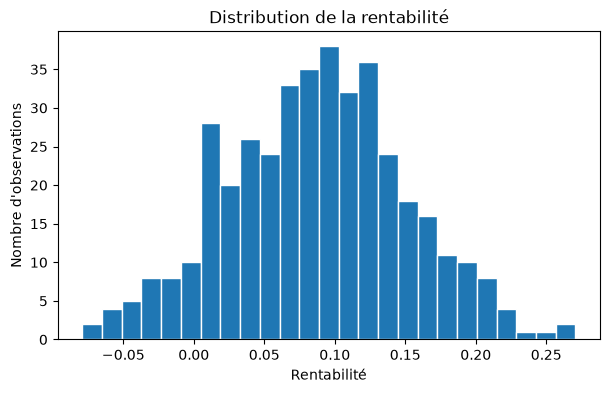

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(df["rentabilite"], bins=25, edgecolor="white")

ax.set_xlabel("Rentabilité")
ax.set_ylabel("Nombre d'observations")
ax.set_title("Distribution de la rentabilité")

plt.show()


L'histogramme permet de voir comment les observations se répartissent selon leurs valeurs. Si la distribution présente une forme relativement symétrique, avec beaucoup d'observations autour du centre et progressivement moins d'observations vers les extrémités, elle peut rappeler une courbe normale.

> **Attention !** Un histogramme ne permet pas, à lui seul, de conclure qu'une variable suit ou ne suit pas une loi normale.

Son apparence dépend notamment du nombre d'observations et du nombre de classes (`bins`) choisi. Pour examiner la normalité plus précisément, nous pouvons utiliser un QQ-plot.

### 2.3. Le QQ-plot

Le **QQ-plot (diagramme quantile-quantile)** est un graphique statistique qui permet de vérifier si un jeu de données suit une loi de probabilité théorique (généralement la loi normale). Il compare les quantiles observés dans nos données avec les quantiles que l'on obtiendrait si les données suivaient une loi normale.  Pour cela, il trace les quantiles observés en fonction des quantiles théoriques attendus. Son principe est relativement simple :

- si les points suivent approximativement la ligne diagonale, les données sont compatibles avec une distribution normale ;
- si les points s'en éloignent fortement, notamment aux extrémités, cela indique un écart par rapport à la normalité.


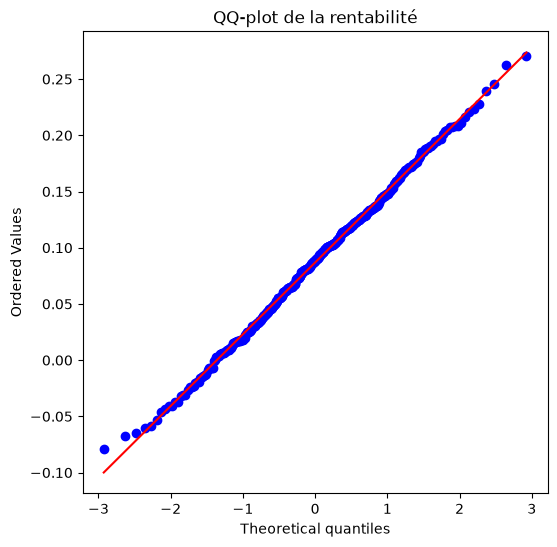

In [11]:
fig, ax = plt.subplots(figsize=(6, 6))

stats.probplot(df["rentabilite"], dist="norm", plot=ax)

ax.set_title("QQ-plot de la rentabilité")

plt.show()


Sur l'axe des X, nous avons les quantiles théoriques.

**Comment interpréter un QQ-plot ?** On compare simplement les quantiles observés dans nos données aux quantiles théoriques d'une loi normale.

- **Distribution proche de la normale :** les points suivent globalement la diagonale.
- **Asymétrie à droite :** les points s'écartent de la diagonale d'une manière indiquant une queue plus longue du côté des grandes valeurs.
- **Asymétrie à gauche :** l'écart est similaire, mais du côté des petites valeurs.
- **Présence de valeurs extrêmes :** quelques points peuvent s'éloigner fortement de la diagonale, notamment aux extrémités du graphique.

```
Normalité              Asymétrie à droite       Asymétrie à gauche
    •                       •                         •
      •                     •                         •
        •                   •                         •
          •                 •                         •
            •               •                         •
              •               •                       •
                •               •                     •
                  •             •                       •
                    •           •                       •
                      •         •                       •
```

Un QQ-plot ne doit pas être interprété uniquement à partir d'un ou deux points. On cherche surtout à observer la forme générale des écarts à la diagonale. 

> **Attention !** Il est vrai que le QQ-plot est un peu plus informatif qu'un simple histogramme pour examiner la normalité. Mais là encore, il s'agit d'un outil d'aide à l'interprétation. Un léger écart à la ligne ne signifie pas nécessairement que l'utilisation d'une méthode statistique est impossible.

### 2.4. Le test de Shapiro-Wilk

Nous pouvons également utiliser un test statistique de normalité. Le **test de Shapiro-Wilk** compare les données observées à ce que l'on attendrait si elles provenaient d'une distribution normale. Pour cela, nous allons utiliser la méthode `shapiro()` de la bibliothèque `scipy.stats` qui permet d'exécuter le test de Shapiro-Wilk en Python.


In [12]:
statistique, p_value = stats.shapiro(df["rentabilite"])   # Calcul

print(f"Statistique = {statistique:.4f}, p-value = {p_value:.4f}") # Affichage

if p_value > 0.05:
    print("On ne rejette pas l'hypothèse de normalité (p > 0.05)")
else:
    print("On rejette l'hypothèse de normalité (p <= 0.05)")


Statistique = 0.9977, p-value = 0.8657
On ne rejette pas l'hypothèse de normalité (p > 0.05)


Ce code nous sert à tester mathématiquement si les rendements financiers (ou gains) contenus dans la colonne `rentabilite` suivent une loi normale.

**Pour le calcul** :

- `df["rentabilite"]` permet d'extraire la colonne `rentabilite` pour l'analyse.
- `stats.shapiro(...)` demande à Python d'appliquer le test de Shapiro-Wilk sur ces données.
- Avec `statistique, p_value =`, le test renvoie deux résultats simultanément (un tuple) qui seront stockés dans deux variables distinctes. On a : `statistique`, avec un score entre 0 et 1. Plus il est proche de 1, plus la forme des données ressemble graphiquement à une loi normale. Ensuite, on a `p_value` qui est la probabilité que l'écart observé entre les données et une vraie loi normale soit uniquement due au hasard. C'est le chiffre le plus important pour prendre une décision.

On affiche le résultat avec l'instruction `print(f"Statistique = {statistique:.4f}, p-value = {p_value:.4f}")`. Le suffixe `:.4f` est une instruction de formatage qui force Python à afficher exactement 4 chiffres après la virgule afin de ne pas avoir un nombre illisible (comme 0.0432198754).

Enfin, pour prendre une décision, on va comparer la `p_value` au seuil standard de `0,05`. Pour le moment :

- si `p_value` < 0,05, on rejette l'hypothèse de normalité ;
- si `p_value` ≥ 0.05, on ne rejette pas l'hypothèse de normalité.


## 3. Tests statistiques (statistiques inférentielles)

Dans les sections précédentes, nous avons appris à décrire nos données : moyenne, médiane, écart-type, distribution, etc. Et dans notre jeu de données, la rentabilité moyenne semble différente selon que les entreprises pratiquent ou non le télétravail. Mais une différence observée dans un échantillon suffit-elle pour conclure qu'il existe réellement une différence dans la population étudiée ? Pour avoir une réponse, il nous faut effectuer des tests statistiques. Ils permettent de savoir si la différence entre deux ou plusieurs moyennes est réelle ou due au hasard.

Maintenant, nous allons pouvoir tester si l'écart de rentabilité entre entreprises en télétravail et les autres est significatif grâce aux tests statistiques ou statistiques inférentielles. Ils regroupent les **méthodes mathématiques qui permettent de tirer des conclusions, d'estimer des paramètres ou de tester des hypothèses** sur une grande population à partir de l'observation d'un échantillon réduit.

### 3.1. Tests paramétriques vs tests non paramétriques

Il existe deux grandes familles de tests statistiques, à savoir **les tests paramétriques** et **les tests non paramétriques**.

Pour les tests paramétriques, on suppose que les données que l’on a à disposition suivent un type de loi de distribution connu (en général la loi normale). Par conséquent, certaines conditions de validité doivent être vérifiées pour que le résultat d’un test paramétrique soit fiable. En revanche, les tests non paramétriques ne nécessitent généralement pas de supposer que les données suivent une distribution normale. Ils reposent sur les rangs ou d'autres propriétés des observations plutôt que directement sur leurs valeurs.

**Tableau comparatif des méthodes statistiques**

| Objectif de l'analyse                                                               | Méthode paramétrique                        | Méthode non paramétrique  |
| ----------------------------------------------------------------------------------- | --------------------------------------------------------------- | --------------------------------------------------------------------- |
| **Comparer 2 groupes indépendants**  <br>_(ex: Hommes vs Femmes)_                   | **Test t de Welch**            | **Test de Mann-Whitney** _(ou Wilcoxon-Mann-Whitney)_                 |
| **Comparer 2 mesures sur le même groupe**  <br>_(ex: Avant vs Après un traitement)_ | **Test t apparié**                                   | **Test des rangs signés de Wilcoxon**                                 |
| **Comparer 3 groupes ou plus**  <br>_(ex: Groupe A vs B vs C)_                      | **ANOVA (Analyse de la variance)** à un facteur                 | **Test de Kruskal-Wallis**                                            |
| **Comparer 3 mesures ou plus (même groupe)**  <br>_(ex: Suivi à T0, T1 et T2)_      | **ANOVA pour mesures répétées**                                 | **Test de Friedman**                                                  |
| **Lier deux variables quantitatives**                                               | **Coefficient de corrélation de Pearson** _(relation linéaire)_ | **Coefficient de corrélation de Spearman** _(relation monotone)_      |
| **Analyser la relation entre 2 variables qualitatives** <br> (catégories)**                                               | Aucune (nécessite des variables quantitatives) | **Test du Chi² d'indépendance**    |


### 3.2. Le principe d'un test d'hypothèse

Un test statistique est un **test d'hypothèse**, parce qu'il s'agit d'une **règle de décision pour valider ou rejeter une hypothèse de départ (hypothèse nulle, H₀)**.  L'hypothèse H₀ est une règle de base en statistique qui suppose l'absence d'effet, de lien ou de différence entre des groupes. Elle sert donc de point de départ neutre que l'on cherche à contredire. Dans notre exemple :

> **H₀ : la rentabilité moyenne est la même pour les entreprises qui pratiquent le télétravail et celles qui ne le pratiquent pas.**

Le test compare ensuite cette hypothèse de départ à ce que nous observons dans nos données. Il produit notamment une `p-value` qui indique dans quelle mesure les données observées sont compatibles avec l'hypothèse nulle H₀. Une `p-value` faible signifie que les données seraient relativement difficiles à obtenir si H₀ était vraie.

Par convention, on utilise souvent un seuil de **5 %**, noté **α = 0,05** :

- si p < 0,05, on rejette H₀ → résultat statistiquement significatif ;
- si p ≥ 0,05, on ne rejette pas H₀ → résultat non statistiquement significatif.

> **Attention !** Ne pas rejeter H₀ ne signifie pas que H₀ est prouvée. Cela signifie simplement que les données ne fournissent pas assez d'éléments pour la rejeter.

**En résumé, les étapes du raisonemment d'un test statistique :** 

- On pose **l'hypothèse nulle (H₀)** : on suppose par défaut qu'il n'y a pas d'effet, pas de lien ou pas de différence.
- On pose ensuite **l'hypothèse alternative (H₁)** qui correspond à l'hypothèse selon laquelle il existe un effet, un lien ou une différence.
- On fixe **le risque (α)** ; un seuil de tolérance (généralement 5 % ou 0,05) d'avoir tort en rejetant H₀ à tort.
- On calcule **la statistique de test** : transformer les données de l'échantillon en une valeur numérique permettant d'évaluer l'écart observé par rapport à H₀ (par exemple, la statistique t pour un test t ou la statistique χ² pour un test du Chi²).
- On prend enfin **une décision** : si la `p-value` est inférieure au seuil α, on rejette H₀. Le résultat est alors considéré comme statistiquement significatif au seuil α.

### 3.3. Comparer deux groupes avec le test t de Welch

Le test t de Welch est un test statistique utilisé pour comparer les moyennes de deux groupes indépendants. C'est une variante du test t de Student classique lorsque les deux groupes ont des tailles d'échantillon ou des variances différentes.

Ici, nous voulons comparer la rentabilité :

- des entreprises sans télétravail ;
- des entreprises avec télétravail.

Commençons donc par créer les deux groupes :


In [13]:
groupe_sans_teletravail = df[df["teletravail"] == 0]["rentabilite"]
groupe_avec_teletravail = df[df["teletravail"] == 1]["rentabilite"]


Nous pouvons ensuite appliquer le test t de Welch avec `stats.ttest_ind()` :


In [14]:
# Appel de la fonction
statistique, p_value = stats.ttest_ind(
    groupe_avec_teletravail,
    groupe_sans_teletravail,
    equal_var=False
)

# Affichage des résultats
print(f"Statistique t = {statistique:.3f}")
print(f"p-value = {p_value:.5f}")


Statistique t = 4.527
p-value = 0.00001


**L'appel de la fonction**

- `stats.ttest_ind(...)`. `ttest_ind()` signifie que l'on compare deux échantillons indépendants. Ici, une *entreprise* appartient soit au groupe « sans télétravail », soit au groupe « avec télétravail ».
- `equal_var=False` indique que nous ne supposons pas que les deux groupes ont la même variance. Python applique alors le test t de Welch, qui est plus robuste lorsque les variances des groupes sont différentes.
- Le tuple de sortie (`statistique, p_value`) : la fonction renvoie deux résultats (la **statistique t** et la **p-value**) qui seront stockés dans deux variables.

Avec `print`, on affiche les résultats, en limitant le nombre de décimales pour faciliter la lecture : `:.3f` arrondit la **statistique t** à 3 chiffres après la virgule et `:.5f` arrondit la `p-value` à 5 chiffres après la virgule.

**Comment interpréter ce résultat ?**

La statistique `t` mesure l'écart entre les deux moyennes en tenant compte de la variabilité des observations. Plus sa valeur absolue est grande, plus les deux moyennes sont éloignées l'une de l'autre relativement à la variabilité des données.

La `p-value`, quant à elle, nous aide à déterminer si l'écart observé est assez important pour remettre en cause H₀. Dans notre exemple, la `p-value` est **très inférieure à 0.05**. Nous rejetons donc H₀. On peut conclure que **la rentabilité moyenne diffère significativement entre les entreprises qui pratiquent le télétravail et celles qui ne le pratiquent pas** ; dans notre échantillon.

> **Attention !** Cette analyse ne permet pas de conclure que le télétravail est une cause de l'augmentation de la rentabilité. Les deux groupes peuvent différer sur d'autres caractéristiques susceptibles d'expliquer cette différence : secteur, taille de l'entreprise, région, etc.

On retient que le test `t` **met en évidence une différence entre deux groupes**, mais ne permet pas à lui seul d'établir une relation causale.

---

> **Pourquoi parle-t-on parfois du test t de Student ?**
> Le test t de Student pour deux échantillons indépendants suppose que les deux groupes ont des variances égales. Le test de Welch ne fait pas cette hypothèse. En pratique, Welch constitue donc un choix plus prudent lorsque l'égalité des variances n'est pas établie.
> Dans scipy.stats.ttest_ind(), equal_var=True correspond au test t de Student classique, tandis que equal_var=False correspond au test t de Welch.

---

### 3.4. Comparer plus de deux groupes avec l'ANOVA

Comme nous venons de le voir, le test `t` permet de comparer deux groupes. Mais que faire si nous voulons comparer la rentabilité moyenne des entreprises appartenant à plusieurs secteurs ? Nous avons alors plus de deux groupes. Pour cela, on peut utiliser une **ANOVA (Analysis of Variance)**.

Dans notre jeu de données, nous pouvons comparer les différents secteurs :

In [15]:
groupes_par_secteur = [
    df[df["secteur"] == secteur]["rentabilite"]
    for secteur in df["secteur"].unique()
]


Nous avons maintenant une liste contenant un échantillon de `rentabilite` pour chaque secteur. Dans le code, nous avons utilisé une **compréhension de liste** en Python qui fait trois choses :

- `df["secteur"].unique()` : identifie tous les secteurs uniques présents dans le DataFrame.
- `df[df["secteur"] == secteur]["rentabilite"]` : pour chaque secteur trouvé, elle filtre le tableau et extrait uniquement la colonne `rentabilite` liée à ce secteur.
- **Résultat :** `groupes_par_secteur` devient une liste de séries de données (une série par secteur), prête à être analysée.

On obtiendra par exemple :

```python
[
    rentabilites_industrie,
    rentabilites_services,
    rentabilites_commerce
]
```

Nous pouvons ensuite transmettre cette liste à `f_oneway()`. La fonction `f_oneway()`, du module `scipy.stats`, permet de réaliser **une analyse de variance à un facteur (ANOVA)**. Elle teste l'hypothèse selon laquelle les moyennes de deux groupes ou plus (indépendants) sont égales :


In [16]:
statistique, p_value = stats.f_oneway(*groupes_par_secteur)

print(f"Statistique F = {statistique:.3f}")
print(f"p-value = {p_value:.5f}")


Statistique F = 1.486
p-value = 0.20562


Pour l'exécution du test avec la fonction `f_oneway()`, on a utilisé l'astérisque `*`. Il faut savoir que `f_oneway` n'accepte pas directement une liste de groupes. Elle attend que vous lui passiez les groupes séparés par des virgules, comme ceci : `f_oneway(groupe1, groupe2, groupe3)`. L'astérisque (`*`) est un opérateur d'unpacking (dépaquetage) qui va prendre notre liste `groupes_par_secteur` et éclater son contenu à l'intérieur de la parenthèse. C'est l'équivalent automatique de : `stats.f_oneway(techno, finance, sante)`. L'avantage est que ce code fonctionne que vous ayez 3 secteurs ou 50 secteurs, sans rien changer au code.

**Comment interpréter l'ANOVA ?**

L'hypothèse nulle de l'ANOVA est :

> H₀ : les moyennes de tous les groupes sont égales.

Si la `p-value` est inférieure à **0.05**, on rejette H₀. Cela signifie qu'il existe une différence statistiquement significative entre les moyennes d'au moins deux groupes.

Mais l'ANOVA ne nous dit pas directement quels groupes sont différents. Pour le déterminer, il faut réaliser d'autres comparaisons appelées **tests post-hoc**. Nous n'aborderons pas ces tests dans ce module introductif.

### 3.5. Que faire lorsque les conditions des tests paramétriques sont fragiles ?

Le **test t** et l'**ANOVA** sont des tests paramétriques. Ils reposent sur certaines hypothèses concernant les données. Le test t est relativement sensible à la présence de distributions très asymétriques, de valeurs extrêmes ou de petits échantillons. Dans certaines situations, on peut utiliser des **tests non paramétriques**, qui reposent sur des hypothèses différentes et sont moins dépendants de la forme précise de la distribution.

Pour comparer deux groupes, on peut utiliser **le test de Mann-Whitney (ou test U)**. C'est un test statistique non paramétrique qui permet de comparer deux groupes indépendants pour savoir si leurs distributions diffèrent. Il sert d'alternative au test t de Welch lorsque les conditions de normalité ne sont pas remplies. Pour effectuer ce test, on va utiliser la fonction `mannwhitneyu` de la bibliothèque Python SciPy :


In [17]:
# Calcul statistique
statistique, p_value = stats.mannwhitneyu(
    groupe_avec_teletravail,
    groupe_sans_teletravail
)

# Affichage des résultats
print(f"Statistique = {statistique:.1f}")
print(f"p-value = {p_value:.5f}")


Statistique = 24986.0
p-value = 0.00001


Le calcul statistique renvoi ici deux éléments :

- `statistique` (la valeur U) : C'est le score calculé par le test. Il est basé sur le classement des données (les rangs) plutôt que sur leurs valeurs brutes.
- `p_value` : qui mesure la probabilité que la différence observée entre les deux groupes soit le fruit du pur hasard.

Si `p-value` < 0.05, la différence est significative. Le télétravail a un réel impact (positif ou négatif) sur la variable mesurée. Si `p-value` ≥ 0.05, la différence n'est pas significative. On considère que le télétravail n'influence pas la variable ou que l'écart observé est un simple hasard.

Pour comparer plus de deux groupes, l'alternative courante à l'ANOVA est le **test de Kruskal-Wallis**.

| Nombre de groupes | Test paramétrique | Alternative non paramétrique |
| ----------------- | ----------------- | ---------------------------- |
| 2 groupes         | Test t            | Mann-Whitney                 |
| Plus de 2 groupes | ANOVA             | Kruskal-Wallis               |


> **Important !** Le choix entre un test paramétrique et un test non paramétrique ne doit pas dépendre uniquement du résultat d'un test de normalité. Il faut également tenir compte de la taille des groupes, de la forme des distributions, des valeurs extrêmes et de la question de recherche.

**À vous de jouer**. Testez maintenant si `satisfaction_rh` diffère significativement selon la pratique du télétravail. Créez deux groupes, puis utilisez un test t de Welch.

**Question :** la p-value obtenue est-elle inférieure à 0.05 ? Que pouvez-vous en conclure ? Attention, votre conclusion doit porter sur une différence entre les deux groupes, et non sur un éventuel effet causal du télétravail.


In [18]:
# Votre code ici


## 4. Tests de corrélation et d'indépendance

Dans la section précédente, nous avons comparé les moyennes de plusieurs groupes. Mais nos questions de recherche ne consistent pas toujours à comparer des groupes. Nous pouvons aussi vouloir savoir si deux variables sont liées. Par exemple :

> Les entreprises qui ont davantage de salariés ont-elles également un chiffre d'affaires plus élevé ?

Ou encore :

> Les entreprises dont la satisfaction RH est plus élevée ont-elles tendance à avoir une meilleure rentabilité ?

Pour répondre à ce type de questions, nous pouvons utiliser des tests de corrélation. Les tests de corrélation **mesurent la force et la direction de la relation entre deux variables**. Le coefficient varie de `-1` à `+1` : une valeur proche de `+1` ou `-1` indique un lien fort, tandis que `0` signifie l'absence de relation. Mais attention ; *une corrélation n'indique pas une causalité*.

### 4.1. Corrélation de Pearson

Le test de Pearson mesure la relation linéaire entre deux variables quantitatives continues qui suivent une loi normale. Le coefficient de corrélation de Pearson, noté `r`, varie entre `-1` et `+1` :

- r = +1 : relation linéaire positive parfaite ;
- r = 0 : aucune relation linéaire ;
- r = -1 : relation linéaire négative parfaite.

Le signe indique le sens de la relation :

- positif : lorsque l'une des variables augmente, l'autre a tendance à augmenter également ;
- négatif : lorsque l'une augmente, l'autre a tendance à diminuer.

La valeur absolue de `r` indique la force de la relation linéaire. Commençons par étudier la relation entre les effectifs et le chiffre d'affaires :


In [19]:
# Calcul de la corrélation
r_pearson, p_pearson = stats.pearsonr(
    df["effectifs"],
    df["chiffre_affaires_keur"]
)

# Affichage des résultats
print(f"r = {r_pearson:.3f}")
print(f"p-value = {p_pearson:.5f}")


r = 0.852
p-value = 0.00000


La fonction `stats.pearsonr()` de la bibliothèque `scipy.stats` calcule le test de Pearson et renvoie simultanément deux valeurs stockées dans deux variables distinctes :

- `r_pearson` (le coefficient `r`) qui mesure la force et le sens de la relation.
- `p_pearson` (la `p-value`) qui mesure la fiabilité statistique du résultat. Elle répond à la question : "Quelle est la probabilité que ce lien soit dû au pur hasard ?"

Ici, `r` est positif et relativement élevé. Cela indique que les entreprises ayant davantage de salariés ont tendance à avoir un chiffre d'affaires plus élevé. La `p-value` permet de tester l'hypothèse nulle :

> H₀ : il n'existe pas de relation linéaire entre les deux variables dans la population.

Si p < 0.05, nous rejetons H₀ et considérons que les données fournissent des éléments en faveur d'une relation linéaire statistiquement significative.

#### Comment interpréter la force d'une corrélation ?

Il n'existe pas de seuil universel qui permette de dire qu'une corrélation est « faible » ou « forte ». L'interprétation dépend notamment du domaine de recherche.

À titre de repère, on peut utiliser :

| Valeur absolue de `r` | Interprétation indicative |
| --------------------: | ------------------------- |
|              `< 0.10` | Négligeable               |
|         `0.10 – 0.30` | Faible                    |
|         `0.30 – 0.50` | Modérée                   |
|              `> 0.50` | Forte                     |

Ces seuils ne doivent pas être considérés comme des règles absolues.

### 4.2. Corrélation de Spearman

La corrélation de Spearman constitue une autre manière de mesurer la relation entre deux variables numériques. Contrairement à Pearson, Spearman ne cherche pas nécessairement une relation linéaire. Il mesure une relation monotone : lorsque l'une des variables augmente, l'autre tend globalement à augmenter ou à diminuer, même si la relation n'est pas parfaitement linéaire.

On peut calculer les deux coefficients :


In [20]:
# Calcul de la corrélation de Pearson
r_pearson, p_pearson = stats.pearsonr(
    df["effectifs"],
    df["chiffre_affaires_keur"]
)

# Calcul de la corrélation de Spearman
r_spearman, p_spearman = stats.spearmanr(
    df["effectifs"],
    df["chiffre_affaires_keur"]
)

# Affichage des résultats
print(f"Pearson  : r = {r_pearson:.3f}, p-value = {p_pearson:.5f}")
print(f"Spearman : r = {r_spearman:.3f}, p-value = {p_spearman:.5f}")

Pearson  : r = 0.852, p-value = 0.00000
Spearman : r = 0.864, p-value = 0.00000


Si les deux coefficients sont proches, cela indique que la relation observée est à la fois monotone et approximativement linéaire.

#### Pearson ou Spearman ?

Pour faire simple :

- Pearson est adapté lorsque l'on cherche une relation linéaire entre deux variables numériques ;
- Spearman est utile lorsque la relation est monotone, mais pas nécessairement linéaire, quand les données présentent des valeurs extrêmes ou ne respectent pas bien les conditions associées à Pearson.

> Avant de calculer une corrélation, regardez aussi vos données graphiquement. Un nuage de points peut vous aider déjà à comprendre la relation.

### 4.3. Corrélation ≠ causalité

En recherche, la corrélation indique que deux variables changent ensemble. Quant à la causalité, elle signifie qu'une variable provoque directement l'autre. Une forte corrélation ne prouve donc jamais un lien de cause à effet, car le lien peut venir du hasard ou d'une troisième variable cachée. Par exemple, supposons que nous trouvions une corrélation positive entre les effectifs et le chiffre d'affaires. On pourrait penser :

> *Les entreprises ont un chiffre d'affaires plus élevé parce qu'elles ont davantage de salariés.*

Mais une autre explication est possible : les grandes entreprises peuvent à la fois employer davantage de salariés et réaliser un chiffre d'affaires plus élevé. La corrélation permet donc de détecter une association, mais pas d'établir à elle seule une relation causale. C'est une distinction que nous retrouverons dans le module 05 consacré à la régression.

### 4.4. Le test du Chi² d'indépendance

Jusqu'ici, nous avons étudié des variables numériques. Mais que faire lorsque nous voulons étudier la relation entre deux variables catégorielles ? Par exemple :

> Le secteur d'activité est-il associé à la taille de l'entreprise ?

Une corrélation de Pearson ou de Spearman n'est pas adaptée à ce type de variables. Nous pouvons utiliser le test du Chi² d'indépendance.

Son hypothèse nulle est :

> H₀ : les deux variables catégorielles sont indépendantes.

Commençons par créer une variable `taille_entreprise` à partir des effectifs :

> **Note**
> Pour pouvoir utiliser le test du Chi², nous devons disposer de deux variables catégorielles. Nous allons donc transformer le nombre d'effectifs, qui est une variable quantitative, en une variable catégorielle représentant la taille de l'entreprise.


In [21]:
df["taille_entreprise"] = df["effectifs"].apply(
    lambda e: "Petite" if e < 50 else ("Moyenne" if e < 250 else "Grande")
)


Nous pouvons ensuite construire un tableau de contingence :

In [22]:
tableau_contingence = pd.crosstab(
    df["secteur"],
    df["taille_entreprise"]
)

tableau_contingence


taille_entreprise,Grande,Moyenne,Petite
secteur,,,
Commerce,43,7,5
Industrie,46,25,5
Santé,44,21,0
Services aux entreprises,55,31,15
Technologies,39,63,5


Ce tableau indique combien d'observations appartiennent à chaque combinaison de secteur et de taille.

Nous pouvons ensuite appliquer le test du Chi² :

In [23]:
statistique, p_value, ddl, valeurs_attendues = stats.chi2_contingency(
    tableau_contingence
)

print(f"Statistique Chi² = {statistique:.3f}")
print(f"p-value = {p_value:.5f}")
print(f"Degrés de liberté = {ddl}")
print(f"Effectifs attendus = {valeurs_attendues}")


Statistique Chi² = 52.481
p-value = 0.00000
Degrés de liberté = 8
Effectifs attendus = [[30.90346535 20.01237624  4.08415842]
 [42.7029703  27.65346535  5.64356436]
 [36.52227723 23.6509901   4.82673267]
 [56.75       36.75        7.5       ]
 [60.12128713 38.93316832  7.94554455]]


**Les quatre éléments retournés :**

- `statistique` : la statistique du Chi² ;
- `p_value` : la p-value du test ;
- `ddl` : les degrés de liberté ;
- `valeurs_attendues` : les effectifs attendus. Elles représentent le nombre d'observations que l'on s'attendrait à trouver dans chaque cellule du tableau si H₀ était vraie, c'est-à-dire si les deux variables étaient indépendantes.

`valeurs_attendues` aura la même structure que `tableau_contingence`, mais avec les effectifs théoriques calculés sous l'hypothèse d'indépendance. Pour obtenir un tableau plus lisible des effectifs attendus, on peut faire :

In [24]:
pd.DataFrame(
    valeurs_attendues,
    index=tableau_contingence.index,
    columns=tableau_contingence.columns
)


taille_entreprise,Grande,Moyenne,Petite
secteur,,,
Commerce,30.903465,20.012376,4.084158
Industrie,42.702970,27.653465,5.643564
Santé,36.522277,23.650990,4.826733
Services aux entreprises,56.750000,36.750000,7.500000
Technologies,60.121287,38.933168,7.945545


Si `p-value` est supérieure à 0.05, nous ne rejetons pas H₀. Nous ne disposons pas encore assez d'éléments pour conclure à une association statistiquement significative entre le secteur et la taille de l'entreprise. Et si `p-value` est inférieur 0,05, nous rejetons H₀ et concluons qu'il existe une association statistiquement significative entre le secteur d'activité et la taille de l'entreprise.

> **Attention !** « Ne pas détecter de relation » ne signifie pas que nous avons démontré que les deux variables sont indépendantes. Cela signifie simplement que le test ne fournit pas suffisamment d'éléments pour rejeter l'hypothèse d'indépendance.

### 4.5. Quel test utiliser ?

On peut retenir ce petit tableau :

| Situation                                    | Test                    |
| -------------------------------------------- | ----------------------- |
| Deux variables numériques, relation linéaire | **Pearson**             |
| Deux variables numériques, relation monotone | **Spearman**            |
| Deux variables catégorielles                 | **Chi² d'indépendance** |


**À vous de jouer** : calculez la corrélation de Pearson entre `rentabilite` et `satisfaction_rh`. Puis répondez aux questions suivantes :

- Le coefficient r est-il positif ou négatif ?
- La corrélation vous semble-t-elle faible, modérée ou forte ?
- La `p-value` indique-t-elle une relation statistiquement significative ?

> **Attention !** Pouvez-vous pour autant conclure que la satisfaction RH cause une meilleure rentabilité ?


In [25]:
# Votre code ici


### 5. Erreurs dans les tests statistiques 

En statistiques, lors d'un test d'hypothèse, on cherche à valider ou rejeter une hypothèse nulle (H₀), qui suppose l'absence d'effet ou de différence. Deux types de décisions incorrectes peuvent survenir :

- **Erreur de type I (Risque α ou première espèce).** Il s'agit d'un faux positif. On conclut à tort qu'il y a un effet ou une différence alors qu'en réalité, il n'y en a pas. L'hypothèse nulle est vraie, mais on la rejette. Le seuil α correspond au risque maximal de type I que l'on accepte dans le cadre du test, sous ses hypothèses et avant l'observation des données. on fixe ce risque à 5 % (0,05).
- **Erreur de type II (Risque β ou seconde espèce).** Il s'agit d'un faux négatif. On conclut à tort qu'il n'y a aucun effet alors qu'un effet réel existe dans la population. L'hypothèse nulle est fausse, mais on ne la rejette pas. La probabilité de détecter un effet réel est appelée puissance statistique (*statistical power*). Elle dépend entre autres de la taille de l'effet, de la taille de l'échantillon, de la variabilité des données, du seuil de significativité choisi, etc.

|                       | **H₀ vraie**        | **H₀ fausse**       |
| --------------------- | ------------------- | ------------------- |
| **Rejeter H₀**        | ❌ Erreur de type I  | ✅ Décision correcte |
| **Ne pas rejeter H₀** | ✅ Décision correcte | ❌ Erreur de type II |


#### Attention aux comparaisons multiples

Un autre problème apparaît lorsque l'on réalise beaucoup de tests statistiques. Supposons que nous testions 20 hypothèses différentes avec un seuil de 5 %. Même si toutes les hypothèses nulles sont réellement vraies, chaque test individuel présente un risque de 5 % de produire un faux positif. Avec plusieurs de tests, il devient alors assez probable d'obtenir au moins un résultat significatif simplement par hasard. C'est le problème des **comparaisons multiples**.

Lorsque de nombreuses hypothèses sont testées, on peut utiliser différentes méthodes pour contrôler ce problème. C'est le cas par exemple de :

- la correction de Bonferroni ;
- la correction de Holm ;
- ou, dans certains contextes, des méthodes qui contrôlent le taux de fausses découvertes (*False Discovery Rate*).

Nous n'entrerons pas dans le détail de ces méthodes dans ce module.

---

Une `p-value` mesure la compatibilité des données avec H₀ ; elle ne mesure ni la probabilité que H₀ soit vraie, ni la taille de l'effet, ni la causalité. Pour un travail de recherche, il est alors préférable de considérer la `p-value` comme une information parmi d'autres, à interpréter avec :

- la taille de l'effet ;
- l'incertitude autour de l'estimation ;
- la taille de l'échantillon ;
- la qualité des données ;
- le contexte théorique ;
- le protocole de recherche...

---


## 6. Intervalles de confiance

Imaginons deux études qui trouvent :

```
Étude A : p = 0.001
Étude B : p = 0.001
```

Cela nous indique dans les deux cas que les données sont peu compatibles avec H₀. Mais cela ne nous dit pas si la différence observée est de 0.001, 0.01 ou 0.10. Pour compléter la `p-value`, on peut utiliser **un intervalle de confiance (IC)**.

### 6.1. Qu'est-ce qu'un intervalle de confiance ?

Un intervalle de confiance est une fourchette de valeurs calculée à partir d'un échantillon qui sert à estimer un paramètre inconnu d'une population entière (comme une moyenne ou une proportion). Il remplace une estimation unique (qui est généralement imprécise) par une plage de valeurs probables et on le fixe à **95 %** ou **99 %**. Un niveau de 95 % signifie que, si l'on répétait l'échantillonnage un grand nombre de fois, 95 % des intervalles ainsi calculés contiendraient la vraie valeur recherchée.

Par exemple, imaginons que nous estimions une différence de rentabilité de **0.028** avec un intervalle de confiance à **95 %** :

```
[0.015 ; 0.041]
```

Cela nous donne beaucoup plus d'informations que la `p-value` à elle seule. Nous savons notamment que :

- l'écart estimé est de 0.028 ;
- les valeurs compatibles avec notre estimation se situent approximativement entre 0.015 et 0.041 selon la procédure utilisée ;
- l'intervalle ne contient pas 0, ce qui est cohérent avec un test t significatif au seuil de 5 %.

### 6.2. Construire un intervalle de confiance à 95 %

Commençons par un cas simple : l'intervalle de confiance de la rentabilité moyenne des entreprises en télétravail.

Nous avons déjà défini ce groupe dans la section 3 :


In [26]:
groupe_avec_teletravail = df[df["teletravail"] == 1]["rentabilite"]


Calculons sa moyenne :

In [27]:
moyenne = groupe_avec_teletravail.mean()

print(f"Moyenne : {moyenne:.4f}")


Moyenne : 0.0988


Pour construire l'intervalle, nous avons besoin de l'erreur standard de la moyenne :

In [28]:
erreur_standard = (
    groupe_avec_teletravail.std()
    / np.sqrt(len(groupe_avec_teletravail))
)

print(f"Erreur standard : {erreur_standard:.4f}")


Erreur standard : 0.0042


L'erreur standard mesure l'incertitude associée à notre estimation de la moyenne : plus l'échantillon est grand, plus l'erreur standard tend à être faible. Nous pouvons maintenant utiliser la distribution t de Student :


In [29]:
intervalle = stats.t.interval(
    0.95,
    df=len(groupe_avec_teletravail) - 1,
    loc=moyenne,
    scale=erreur_standard
)

print(
    f"IC à 95 % : "
    f"[{intervalle[0]:.4f}, {intervalle[1]:.4f}]"
)


IC à 95 % : [0.0906, 0.1070]


### 6.3. Comment interpréter un IC à 95 % ?

Une formulation rigoureuse est :

> Si nous répétions un très grand nombre de fois le même processus d'échantillonnage et que nous construisions à chaque fois un intervalle de confiance à 95 %, environ 95 % de ces intervalles contiendraient la vraie valeur du paramètre dans la population.

En revanche, il n'est pas rigoureusement correct de dire :

> ❌ "Il y a 95 % de chances que la vraie moyenne se trouve dans cet intervalle."

Dans l'approche fréquentiste utilisée ici, la vraie moyenne est considérée comme une valeur fixe ; c'est l'intervalle qui varie d'un échantillon à l'autre. Pour un cours introductif, vous pouvez retenir simplement :

> Un IC à 95 % donne une plage de valeurs plausibles pour le paramètre que nous cherchons à estimer, compte tenu de nos données et de notre méthode d'estimation.

### 6.4. L'intervalle de confiance de la différence

Dans notre question de recherche, nous ne cherchons pas seulement à connaître la rentabilité moyenne de chaque groupe. Nous voulons surtout savoir :

> **Quelle est la différence de rentabilité entre les entreprises avec et sans télétravail ?**

Calculons donc directement cette différence :


In [30]:
difference = (
    groupe_avec_teletravail.mean()
    - groupe_sans_teletravail.mean()
)

print(f"Différence de moyennes : {difference:.4f}")


Différence de moyennes : 0.0281


Cette différence est notre estimation de l'effet. Mais une estimation seule ne suffit pas ; elle est elle-même incertaine. Nous pouvons donc calculer son intervalle de confiance à 95 %.


In [31]:
resultat = stats.ttest_ind(
    groupe_avec_teletravail,
    groupe_sans_teletravail,
    equal_var=False
)

print(resultat)


TtestResult(statistic=np.float64(4.526671187454562), pvalue=np.float64(8.04075120692227e-06), df=np.float64(377.83190306847183))


Ici, nous utilisons `equal_var=False` : il s'agit du test t de Welch, qui ne suppose pas que les deux groupes aient exactement la même variance. Pour obtenir l'intervalle de confiance de la différence, on peut utiliser :


In [32]:
moyenne_avec = groupe_avec_teletravail.mean()
moyenne_sans = groupe_sans_teletravail.mean()

n_avec = len(groupe_avec_teletravail)
n_sans = len(groupe_sans_teletravail)

var_avec = groupe_avec_teletravail.var()
var_sans = groupe_sans_teletravail.var()

erreur_standard_diff = np.sqrt(
    var_avec / n_avec +
    var_sans / n_sans
)

ddl = (
    (var_avec / n_avec + var_sans / n_sans) ** 2
    /
    (
        (var_avec / n_avec) ** 2 / (n_avec - 1)
        +
        (var_sans / n_sans) ** 2 / (n_sans - 1)
    )
)

alpha = 0.05

t_critique = stats.t.ppf(1 - alpha / 2, ddl)

borne_inferieure = difference - t_critique * erreur_standard_diff
borne_superieure = difference + t_critique * erreur_standard_diff

print(f"Différence : {difference:.4f}")
print(
    f"IC à 95 % : "
    f"[{borne_inferieure:.4f}, {borne_superieure:.4f}]"
)


Différence : 0.0281
IC à 95 % : [0.0159, 0.0403]


Cela peut sembler plus long que les calculs précédents, mais chaque élément correspond à une idée statistique importante :

- `difference` : différence observée entre les deux moyennes ;
- `erreur_standard_diff` : incertitude autour de cette différence ;
- `ddl` : degrés de liberté utilisés par le test de Welch ;
- `t_critique` : valeur critique de la distribution t ;
- les deux bornes : limites de notre intervalle de confiance.

### 6.5. Le lien entre intervalle de confiance et test d'hypothèse

Il existe un lien très utile entre les deux notions. Pour un test bilatéral au seuil de 5 %, si l'intervalle de confiance à 95 % de la différence entre deux groupes ne contient pas 0, cela correspond à un rejet de H₀ au seuil de 5 %.

**Pourquoi 0 ?** Parce que notre H₀ affirme qu'*il n'y a pas de différence entre les deux groupes*.

Mathématiquement :

```
H₀ : μ₁ - μ₂ = 0
```

Donc :

- IC contient 0 → la différence n'est pas statistiquement significative au seuil de 5 % ;
- IC ne contient pas 0 → la différence est statistiquement significative au seuil de 5 %.

Mais l'intervalle apporte une autre information. Il nous indique quelles valeurs de la différence sont compatibles avec les données.

### 6.6. Pourquoi l'IC donne plus d'information que la p-value à elle seule ?

Supposons deux résultats :

**Résultat A**

```
Différence = 0.003
IC 95 % = [0.001 ; 0.005]
p < 0.05
```

La différence est statistiquement significative, mais son ampleur est relativement faible.

**Résultat B**

```
Différence = 0.040
IC 95 % = [0.015 ; 0.065]
p < 0.05
```

La différence est également statistiquement significative, mais son ampleur est beaucoup plus importante.

La seule mention **p < 0.05** ne permettrait pas de distinguer clairement ces deux situations. La significativité statistique ne dit donc pas nécessairement si un effet est important en pratique. C'est pourquoi, dans un travail de recherche, il est préférable de rapporter :

- l'estimation de l'effet ;
- son intervalle de confiance ;
- et la p-value.

## À vous de jouer

Calculez l'intervalle de confiance à 95 % de la différence de rentabilité moyenne entre les entreprises avec et sans télétravail. Vous pouvez utiliser :

```
groupe_avec_teletravail
groupe_sans_teletravail
```

**Questions :**

- Quelle est la différence de rentabilité moyenne entre les deux groupes ?
- Quel est son intervalle de confiance à 95 % ?
- L'intervalle contient-il 0 ?
- Votre conclusion est-elle cohérente avec le test t réalisé en section 3 ?


In [33]:
# Votre code ici


## Retour sur notre question de recherche

Nous pouvons maintenant répondre avec plus de précision à notre question de recherche. Dans notre échantillon, nous observons une différence de rentabilité moyenne entre les entreprises qui pratiquent le télétravail et celles qui ne le pratiquent pas. Le test t indique que cette différence est statistiquement significative au seuil de 5 % et l'intervalle de confiance permet en plus d'en apprécier l'ampleur et l'incertitude. Mais une limite demeure :

> Nous avons mis en évidence une association, pas une causalité.

Les entreprises qui pratiquent le télétravail être différentes de celles qui ne le pratiquent pas sur des caractéristiques telles que *le secteur*, *la taille*, *l'année*, *l'organisation*, *les pratiques managériales*, etc. La comparaison de deux moyennes ne permet pas de contrôler simultanément ces facteurs. Et c'est la question à laquelle nous allons nous attaquer dans le prochain module :

> **Comment estimer l'association entre le télétravail et la performance tout en contrôlant d'autres variables ?**

C'est l'objet du module 05 sur l'économétrie, avec notamment la régression linéaire multiple.


## À vous de jouer

Quatre exercices dans le dossier [`exercices/`](exercices/) :
- **Exercice 1** : statistiques descriptives et détection d'anomalies
- **Exercice 2** : tester si deux groupes diffèrent significativement
- **Exercice 3** : tester une corrélation et un lien d'indépendance
- **Exercice 4** : construire et interpréter un intervalle de confiance

Corrigés disponibles dans [`solutions/04-stats-descriptives-inferentielles/`](../../solutions/04-stats-descriptives-inferentielles/).


## Suite

Selon votre objectif (voir la [roadmap](../../docs/roadmap.md)) :
- Vers l'[économétrie](../05-econometrie/) pour contrôler d'autres facteurs et se rapprocher d'une inférence causale
- Vers le [machine learning](../08-machine-learning-intro/) pour des approches prédictives
